# Problem Statement

**Food Delivery services like Zomato and Swiggy need to show the accurate time it will take to deliver your order to keep transparency with their customers. These companies use Machine Learning algorithms to predict the food delivery time based on how much time the delivery partners took for the same distance in the past.**

**To predict the food delivery time in real-time, we need to calculate the distance between the food preparation point and the point of food consumption. After finding the distance between the restaurant and the delivery locations, we need to find relationships between the time taken by delivery partners to deliver the food in the past for the same distance.**


In [1]:
#Importatnt Libraries
import pandas as pd
import numpy as numpy
import matplotlib.pyplot as plt 
import seaborn as sns 

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning) 

from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler ,OrdinalEncoder ,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

from sklearn.impute import KNNImputer

In [2]:
df = pd.read_csv(r'D:\Project2\ModularCoding1\notebook\data\finalTrain.csv')

In [3]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min)
0,0xcdcd,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,12-02-2022,21:55,22:10,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46
1,0xd987,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,13-02-2022,14:55,15:05,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23
2,0x2784,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,04-03-2022,17:30,17:40,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21
3,0xc8b6,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,13-02-2022,09:20,09:30,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20
4,0xdb64,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,14-02-2022,19:50,20:05,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41


In [4]:
df.shape

(45584, 20)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45584 entries, 0 to 45583
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45584 non-null  object 
 1   Delivery_person_ID           45584 non-null  object 
 2   Delivery_person_Age          43730 non-null  float64
 3   Delivery_person_Ratings      43676 non-null  float64
 4   Restaurant_latitude          45584 non-null  float64
 5   Restaurant_longitude         45584 non-null  float64
 6   Delivery_location_latitude   45584 non-null  float64
 7   Delivery_location_longitude  45584 non-null  float64
 8   Order_Date                   45584 non-null  object 
 9   Time_Orderd                  43853 non-null  object 
 10  Time_Order_picked            45584 non-null  object 
 11  Weather_conditions           44968 non-null  object 
 12  Road_traffic_density         44983 non-null  object 
 13  Vehicle_conditio

In [6]:
df.isnull().sum()

ID                                0
Delivery_person_ID                0
Delivery_person_Age            1854
Delivery_person_Ratings        1908
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Order_Date                        0
Time_Orderd                    1731
Time_Order_picked                 0
Weather_conditions              616
Road_traffic_density            601
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             993
Festival                        228
City                           1200
Time_taken (min)                  0
dtype: int64

In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Delivery_person_Age,43730.0,29.566911,5.815064,15.000000,25.000000,30.000000,35.000000,50.000000
Delivery_person_Ratings,43676.0,4.633774,0.334744,1.000000,4.500000,4.700000,4.900000,6.000000
Restaurant_latitude,45584.0,17.017948,8.185674,-30.905562,12.933284,18.551440,22.728163,30.914057
Restaurant_longitude,45584.0,70.229684,22.885575,-88.366217,73.170000,75.897963,78.044095,88.433452
Delivery_location_latitude,45584.0,17.465480,7.335562,0.010000,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45584.0,70.844161,21.120578,0.010000,73.280000,76.002574,78.107044,88.563452
Vehicle_condition,45584.0,1.023385,0.839055,0.000000,0.000000,1.000000,2.000000,3.000000
multiple_deliveries,44591.0,0.744635,0.572510,0.000000,0.000000,1.000000,1.000000,3.000000
Time_taken (min),45584.0,26.293963,9.384298,10.000000,19.000000,26.000000,32.000000,54.000000


In [8]:
#Getting Unique Values From Dataset 
for column in df.columns:
    print("{} column from dataset contain {} unique value".format(column,df[column].nunique()))
    if df[column].nunique() < 8:
        print("Total unique values in {} column in dataset are {}".format(column , df[column].unique()))
    print('*' * 35)
    print()
    

ID column from dataset contain 45584 unique value
***********************************

Delivery_person_ID column from dataset contain 1320 unique value
***********************************

Delivery_person_Age column from dataset contain 22 unique value
***********************************

Delivery_person_Ratings column from dataset contain 28 unique value
***********************************

Restaurant_latitude column from dataset contain 657 unique value
***********************************

Restaurant_longitude column from dataset contain 518 unique value
***********************************

Delivery_location_latitude column from dataset contain 4373 unique value
***********************************

Delivery_location_longitude column from dataset contain 4373 unique value
***********************************

Order_Date column from dataset contain 44 unique value
***********************************

Time_Orderd column from dataset contain 176 unique value
******************************

In [9]:
features = []
dtypes = []
count = []
unique = []
missing = []
missing_percentage = []

for column in df.columns:
    features.append(column)
    dtypes.append(df[column].dtype)
    count.append(len(df[column]))
    unique.append(df[column].nunique())
    missing.append(df[column].isnull().sum())
    missing_percentage.append(round((df[column].isnull().sum())/(len(df[column])),4)*100)
    

dataframe = pd.DataFrame(
    {"Feature" : features ,
     "count" : count,
    "dtypes" :dtypes,
    "unique" : unique ,
    "missing" : missing ,
    "missing_percentage" : missing_percentage}
)
dataframe.set_index('Feature')
    

,count,dtypes,unique,missing,missing_percentage
Feature,,,,,
ID,45584,object,45584,0,0.00
Delivery_person_ID,45584,object,1320,0,0.00
Delivery_person_Age,45584,float64,22,1854,4.07
Delivery_person_Ratings,45584,float64,28,1908,4.19
Restaurant_latitude,45584,float64,657,0,0.00
Restaurant_longitude,45584,float64,518,0,0.00
Delivery_location_latitude,45584,float64,4373,0,0.00
Delivery_location_longitude,45584,float64,4373,0,0.00
Order_Date,45584,object,44,0,0.00


Few columns from dataset are not important .We have to drop them else they may increase complexity

In [10]:
df.drop(columns=['ID'],inplace=True)

In [11]:
df.columns

Index(['Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings',
       'Restaurant_latitude', 'Restaurant_longitude',
       'Delivery_location_latitude', 'Delivery_location_longitude',
       'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weather_conditions',
       'Road_traffic_density', 'Vehicle_condition', 'Type_of_order',
       'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City',
       'Time_taken (min)'],
      dtype='object')

In [12]:
#We will convert Datatype of Order_Date column into Datetime 
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

C:\Users\pramod.khavare\AppData\Roaming\Python\Python310\site-packages\pandas\core\tools\datetimes.py:1047: UserWarning: Parsing '13-02-2022' in DD/MM/YYYY format. Provide format or specify infer_datetime_format=True for consistent parsing.
  cache_array = _maybe_cache(arg, format, cache, convert_listlike)
C:\Users\pramod.khavare\AppData\Roaming\Python\Python310\site-packages\pandas\core\tools\datetimes.py:1047: UserWarning: Parsing '14-02-2022' in DD/MM/YYYY format. Provide format or specify infer_datetime_format=True for consistent parsing.
  cache_array = _maybe_cache(arg, format, cache, convert_listlike)
C:\Users\pramod.khavare\AppData\Roaming\Python\Python310\site-packages\pandas\core\tools\datetimes.py:1047: UserWarning: Parsing '16-03-2022' in DD/MM/YYYY format. Provide format or specify infer_datetime_format=True for consistent parsing.
  cache_array = _maybe_cache(arg, format, cache, convert_listlike)
C:\Users\pramod.khavare\AppData\Roaming\Python\Python310\site-packages\panda

In [13]:
df['Order_Date']

0       2022-12-02
1       2022-02-13
2       2022-04-03
3       2022-02-13
4       2022-02-14
           ...    
45579   2022-03-24
45580   2022-02-16
45581   2022-11-03
45582   2022-07-03
45583   2022-02-03
Name: Order_Date, Length: 45584, dtype: datetime64[ns]

In [14]:
#We will store Date Year and Day column in diffrent diffrent column

df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Day'] = df['Order_Date'].dt.day

In [15]:
df.head()

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,...,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),Year,Month,Day
0,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,2022-12-02,21:55,22:10,...,2,Snack,motorcycle,3.0,No,Metropolitian,46,2022,12,2
1,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,2022-02-13,14:55,15:05,...,1,Meal,motorcycle,1.0,No,Metropolitian,23,2022,2,13
2,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,2022-04-03,17:30,17:40,...,1,Drinks,scooter,1.0,No,Metropolitian,21,2022,4,3
3,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,2022-02-13,09:20,09:30,...,0,Buffet,motorcycle,0.0,No,Metropolitian,20,2022,2,13
4,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,2022-02-14,19:50,20:05,...,1,Snack,scooter,1.0,No,Metropolitian,41,2022,2,14


In [16]:
#Remove Date column from dataset 
df.drop(columns=['Order_Date'] , inplace=True)

In [17]:
df.dropna(subset=['Time_Orderd'] ,inplace=True)  #subset will help to remove na values from row of perticuler column

In [18]:
df['Time_Orderd'].unique()

array(['21:55', '14:55', '17:30', '09:20', '19:50', '20:25', '20:30',
       '20:40', '21:15', '20:20', '22:30', '08:15', '19:30', '12:25',
       '18:35', '20:35', '23:20', '21:20', '23:35', '22:35', '23:25',
       '13:35', '21:35', '18:55', '14:15', '0.458333333', '09:45',
       '08:40', '0.958333333', '17:25', '19:45', '19:10', '10:55',
       '21:40', '0.791666667', '16:45', '11:30', '15:10', '22:45',
       '22:10', '20:45', '22:50', '17:55', '09:25', '20:15', '22:25',
       '22:40', '23:50', '15:25', '10:20', '20:55', '10:40', '15:55',
       '20:10', '12:10', '15:30', '10:35', '21:10', '20:50', '12:35',
       '0.875', '23:40', '18:15', '18:20', '11:45', '12:45', '23:30',
       '10:50', '21:25', '10:10', '17:50', '22:20', '12:40', '23:55',
       '10:25', '08:45', '23:45', '19:55', '22:15', '23:10', '09:15',
       '18:25', '18:45', '16:50', '1', '14:20', '10:15', '08:50', '0.375',
       '17:45', '16:35', '08:30', '21:45', '19:40', '14:50', '18:10',
       '12:20', '12:50',

In [19]:
df['Time_Orderd'] = df['Time_Orderd'].str.replace('.',':')

C:\Users\pramod.khavare\AppData\Local\Temp\ipykernel_26936\3853550708.py:1: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  df['Time_Orderd'] = df['Time_Orderd'].str.replace('.',':')


In [20]:


def extract(x):
    try:
        return x.split(':')[0] + ':' + x.split(':')[1][0:2]
        
    except IndexError :
        return '00:00'
    
df['Time_Orderd'] = df['Time_Orderd'].apply(extract)

In [21]:
df['Time_Orderd'].unique()

array(['21:55', '14:55', '17:30', '09:20', '19:50', '20:25', '20:30',
       '20:40', '21:15', '20:20', '22:30', '08:15', '19:30', '12:25',
       '18:35', '20:35', '23:20', '21:20', '23:35', '22:35', '23:25',
       '13:35', '21:35', '18:55', '14:15', '0:45', '09:45', '08:40',
       '0:95', '17:25', '19:45', '19:10', '10:55', '21:40', '0:79',
       '16:45', '11:30', '15:10', '22:45', '22:10', '20:45', '22:50',
       '17:55', '09:25', '20:15', '22:25', '22:40', '23:50', '15:25',
       '10:20', '20:55', '10:40', '15:55', '20:10', '12:10', '15:30',
       '10:35', '21:10', '20:50', '12:35', '0:87', '23:40', '18:15',
       '18:20', '11:45', '12:45', '23:30', '10:50', '21:25', '10:10',
       '17:50', '22:20', '12:40', '23:55', '10:25', '08:45', '23:45',
       '19:55', '22:15', '23:10', '09:15', '18:25', '18:45', '16:50',
       '00:00', '14:20', '10:15', '08:50', '0:37', '17:45', '16:35',
       '08:30', '21:45', '19:40', '14:50', '18:10', '12:20', '12:50',
       '09:10', '12:30', 

In [22]:
df['Time_Orderd']=pd.to_datetime(df['Time_Orderd'] ,format='%H:%M:%S' ,errors='ignore')

In [23]:
df['TimeOrder_Hour'] = df['Time_Orderd'].str.split(':' , expand=True)[0]


df['TimeOrder_Hour']=df['TimeOrder_Hour'].str.replace('0' ,'00')
df['TimeOrder_Hour']=df['TimeOrder_Hour'].astype('int32')


In [24]:

df['TimeOrder_Min'] = df['Time_Orderd'].str.split(':' ,expand=True)[1]

df['TimeOrder_Min']=df['TimeOrder_Min'].str.replace('0' ,'00')

df['TimeOrder_Min'] = df['TimeOrder_Min'].astype('int32')

In [25]:
df.head()

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_Orderd,Time_Order_picked,Weather_conditions,...,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min
0,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,21:55,22:10,Fog,...,motorcycle,3.0,No,Metropolitian,46,2022,12,2,21,55
1,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,14:55,15:05,Stormy,...,motorcycle,1.0,No,Metropolitian,23,2022,2,13,14,55
2,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,17:30,17:40,Sandstorms,...,scooter,1.0,No,Metropolitian,21,2022,4,3,17,300
3,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,09:20,09:30,Sandstorms,...,motorcycle,0.0,No,Metropolitian,20,2022,2,13,9,200
4,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,19:50,20:05,Fog,...,scooter,1.0,No,Metropolitian,41,2022,2,14,19,500


In [26]:
df.drop(columns=['Time_Orderd'] ,inplace=True)

In TimeOrder_Hour:
1. 7AM - 12PM  :-Breakfast
2. 12Pm - 15PM :-Lunch
3. 15PM -17PM  :-After Lunch
4. 17PM - 19PM :-Evening Snacks
5. 19PM -24AM  :-Dinner

Preprocessing of column :Time_Order_picked

In [27]:
df['Time_Order_picked'].unique()

array(['22:10', '15:05', '17:40', '09:30', '20:05', '20:35', '15:10',
       '20:40', '20:50', '21:30', '20:25', '22:45', '08:30', '19:45',
       '12:30', '18:50', '23:30', '21:35', '23:45', '22:50', '22:40',
       '23:35', '13:40', '21:45', '19:10', '14:25', '11:10', '09:55',
       '08:55', '23:10', '17:30', '19:50', '19:25', '0.458333333',
       '19:15', '16:55', '11:40', '15:15', '22:55', '22:25', '20:55',
       '23:05', '0.75', '0.958333333', '09:40', '20:20', '22:35',
       '0.916666667', '23:55', '15:40', '10:30', '0.875', '10:50',
       '16:05', '20:15', '12:15', '15:45', '22:15', '10:45', '24:05:00',
       '21:25', '12:45', '21:15', '18:20', '18:25', '11:50', '12:50',
       '10:55', '21:40', '10:20', '17:55', '23:50', '12:55', '24:10:00',
       '10:40', '0.375', '20:45', '0.833333333', '23:15', '18:35',
       '22:20', '21:05', '0.708333333', '24:15:00', '21:20', '14:35',
       '10:25', '09:05', '16:50', '08:40', '23:40', '21:50', '19:55',
       '0.625', '10:35', '0

In [28]:
df['Time_Order_picked'] = df['Time_Order_picked'].str.replace('.',':')

C:\Users\pramod.khavare\AppData\Local\Temp\ipykernel_26936\3274878804.py:1: FutureWarning: The default value of regex will change from True to False in a future version. In addition, single character regular expressions will *not* be treated as literal strings when regex=True.
  df['Time_Order_picked'] = df['Time_Order_picked'].str.replace('.',':')


In [29]:
def extract(x):
    try:
        return x.split(':')[0] + ':' + x.split(':')[1][0:2]
        
    except IndexError :
        return '00:00'
    
df['Time_Order_picked'] = df['Time_Order_picked'].apply(extract)

In [30]:
df['Time_Order_picked'].unique()

array(['22:10', '15:05', '17:40', '09:30', '20:05', '20:35', '15:10',
       '20:40', '20:50', '21:30', '20:25', '22:45', '08:30', '19:45',
       '12:30', '18:50', '23:30', '21:35', '23:45', '22:50', '22:40',
       '23:35', '13:40', '21:45', '19:10', '14:25', '11:10', '09:55',
       '08:55', '23:10', '17:30', '19:50', '19:25', '0:45', '19:15',
       '16:55', '11:40', '15:15', '22:55', '22:25', '20:55', '23:05',
       '0:75', '0:95', '09:40', '20:20', '22:35', '0:91', '23:55',
       '15:40', '10:30', '0:87', '10:50', '16:05', '20:15', '12:15',
       '15:45', '22:15', '10:45', '24:05', '21:25', '12:45', '21:15',
       '18:20', '18:25', '11:50', '12:50', '10:55', '21:40', '10:20',
       '17:55', '23:50', '12:55', '24:10', '10:40', '0:37', '20:45',
       '0:83', '23:15', '18:35', '22:20', '21:05', '0:70', '24:15',
       '21:20', '14:35', '10:25', '09:05', '16:50', '08:40', '23:40',
       '21:50', '19:55', '0:62', '10:35', '09:25', '17:20', '19:30',
       '17:25', '20:10', '00:

In [31]:
df['Time_Order_picked']=pd.to_datetime(df['Time_Order_picked'] ,format='%H:%M:%S' ,errors='ignore')

In [32]:
#Order Hour
df['Time_Order_picked_hour'] = df['Time_Order_picked'].str.split(':' , expand=True)[0]


df['Time_Order_picked_hour']=df['Time_Order_picked_hour'].astype('int32')



In [33]:
#Order Min
df['Time_Order_picked_min'] = df['Time_Order_picked'].str.split(':' , expand=True)[1]
df['Time_Order_picked_min'] = df['Time_Order_picked_min'].astype('int32')

#### Extract city from delivery_person_id:-

In [34]:
df['Delivery_city'] = df['Delivery_person_ID'].str.split('RES' ,expand=True)[0]

In [35]:
df.head()

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_Order_picked,Weather_conditions,Road_traffic_density,...,City,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min,Time_Order_picked_hour,Time_Order_picked_min,Delivery_city
0,DEHRES17DEL01,36.0,4.2,30.327968,78.046106,30.397968,78.116106,22:10,Fog,Jam,...,Metropolitian,46,2022,12,2,21,55,22,10,DEH
1,KOCRES16DEL01,21.0,4.7,10.003064,76.307589,10.043064,76.347589,15:05,Stormy,High,...,Metropolitian,23,2022,2,13,14,55,15,5,KOC
2,PUNERES13DEL03,23.0,4.7,18.562450,73.916619,18.652450,74.006619,17:40,Sandstorms,Medium,...,Metropolitian,21,2022,4,3,17,300,17,40,PUNE
3,LUDHRES15DEL02,34.0,4.3,30.899584,75.809346,30.919584,75.829346,09:30,Sandstorms,Low,...,Metropolitian,20,2022,2,13,9,200,9,30,LUDH
4,KNPRES14DEL02,24.0,4.7,26.463504,80.372929,26.593504,80.502929,20:05,Fog,Jam,...,Metropolitian,41,2022,2,14,19,500,20,5,KNP


In [36]:
df['Delivery_city'].unique()

array(['DEH', 'KOC', 'PUNE', 'LUDH', 'KNP', 'MUM', 'MYS', 'HYD', 'KOL',
       'RANCHI', 'COIMB', 'CHEN', 'JAP', 'SUR', 'BANG', 'GOA', 'AURG',
       'AGR', 'VAD', 'ALH', 'BHP', 'INDO'], dtype=object)

In [37]:
df['Restaurant_latitude'].dtype

dtype('float64')

#### Handling missing values in Delivery Person Rating

In [38]:
df['Delivery_person_Ratings'].isnull().sum()

268

In [39]:
import numpy as np

In [40]:
#Filling null value in Rating 
rating_map = np.round(df.groupby('Delivery_person_ID')['Delivery_person_Ratings'].agg('mean'),1).to_dict()
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].fillna(df['Delivery_person_ID'].map(rating_map))

In [41]:
df['Delivery_person_Ratings'].isnull().sum()


0

### Visualization:-

In [42]:
import folium
folium.Map(title = 'cartodb positron')

In [43]:
import folium
folium.Map(tiles= 'cartodb positron')

In [44]:
import plotly.express as px
data1 = df.copy()
data1.isnull().sum()

Delivery_person_ID                0
Delivery_person_Age             214
Delivery_person_Ratings           0
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Time_Order_picked                 0
Weather_conditions                0
Road_traffic_density              0
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             943
Festival                        219
City                           1144
Time_taken (min)                  0
Year                              0
Month                             0
Day                               0
TimeOrder_Hour                    0
TimeOrder_Min                     0
Time_Order_picked_hour            0
Time_Order_picked_min             0
Delivery_city                     0
dtype: int64

In [45]:
data1.dropna(axis=0 , how = 'any' , thresh=None , subset= None ,inplace=True)
color_scale = [(0, 'orange'),(1,'red')]
fig = px.scatter_mapbox(
    data1 ,lat='Restaurant_latitude',
    lon = 'Restaurant_longitude',
    color_continuous_scale= color_scale ,
    zoom=8,
    height=1000,
    width=1000
)
fig.update_layout(mapbox_style = 'open-street-map')
fig.update_layout(margin={'r':0 ,'t':0 ,'l':0,'b':0})
fig.show()


In [46]:
#Convert negative latitude into positive latitude

df['Restaurant_latitude'] = df['Restaurant_latitude'].abs()

In [47]:
data1.dropna(axis=0 , how = 'any' , thresh=None , subset= None ,inplace=True)
color_scale = [(0, 'orange'),(1,'red')]
fig = px.scatter_mapbox(
    df ,lat='Restaurant_latitude',
    lon = 'Restaurant_longitude',
    color_continuous_scale= color_scale ,
    zoom=8,
    height=1000,
    width=1000
)
fig.update_layout(mapbox_style = 'open-street-map')
fig.update_layout(margin={'r':0 ,'t':0 ,'l':0,'b':0})
fig.show()

In [48]:
#Calulate distance in between two point on earth (use Haversine Formula)
import math 
def distance(lat1 ,long1 ,lat2 ,long2):
    #convert latitude and langitude in radian
    lat1 ,long1 ,lat2 ,long2  = map(math.radians, [lat1 ,long1 ,lat2 ,long2])
    
    #Haversine Formula
    dlat =lat2 - lat1
    dlon =long2 - long1
    
    a = math.sin(dlat/2)**2 + math.cos(lat1) * math.cos(lat2) *math.sin(dlon/2)**2
    c = 2 * math.atan2(math.sqrt(a) , math.sqrt(1-a))
    R = 6371.0  #Earth radius in km
    
    dist = R * c
    
    return dist



In [49]:
def distance_numpy( df, lat1, lon1,lat2, lon2 ):
        p = np.pi/180
        a = 0.5 - np.cos((df[lat2]-df[lat1])*p)/2 + np.cos(df[lat1]*p) * np.cos(df[lat2]*p) * (1-np.cos((df[lon2]-df[lon1])*p))/2
        abc = 12734 * np.arccos(np.sort(a))
        print(abc)

In [50]:
df.iloc[1]

Delivery_person_ID             KOCRES16DEL01
Delivery_person_Age                     21.0
Delivery_person_Ratings                  4.7
Restaurant_latitude                10.003064
Restaurant_longitude               76.307589
Delivery_location_latitude         10.043064
Delivery_location_longitude        76.347589
Time_Order_picked                      15:05
Weather_conditions                    Stormy
Road_traffic_density                    High
Vehicle_condition                          1
Type_of_order                           Meal
Type_of_vehicle                   motorcycle
multiple_deliveries                      1.0
Festival                                  No
City                           Metropolitian
Time_taken (min)                          23
Year                                    2022
Month                                      2
Day                                       13
TimeOrder_Hour                            14
TimeOrder_Min                             55
Time_Order

In [51]:
df['Distance'] = df.apply(lambda x : distance(x['Restaurant_latitude'] , x['Restaurant_longitude'] , x['Delivery_location_latitude'] ,x['Delivery_location_longitude']),axis=1)


In [52]:
df['Distance']

0        10.280582
1         6.242319
2        13.787860
3         2.930258
4        19.396618
           ...    
45579     1.489846
45580    11.007735
45581     4.657195
45582     6.232393
45583    12.074396
Name: Distance, Length: 43853, dtype: float64

In [53]:
distance_numpy(df ,'Restaurant_latitude' ,'Restaurant_longitude' ,'Delivery_location_latitude' ,'Delivery_location_longitude')

[20002.52025706 20002.52025706 20002.52025706 ... 20002.48593765
 20002.48593765 20002.48593765]


In [54]:
df.groupby(['Restaurant_latitude' ,'Restaurant_longitude','Delivery_location_latitude' , 'Delivery_location_longitude'])['Distance'].max().head(40)

Restaurant_latitude  Restaurant_longitude  Delivery_location_latitude  Delivery_location_longitude
0.000000             0.000000              0.010000                    0.010000                        1.572534
                                           0.020000                    0.020000                        3.145067
                                           0.030000                    0.030000                        4.717601
                                           0.040000                    0.040000                        6.290135
                                           0.050000                    0.050000                        7.862668
                                           0.060000                    0.060000                        9.435202
                                           0.070000                    0.070000                       11.007735
                                           0.080000                    0.080000                       12.580268
     

In [55]:
# order from restorent Restorent location == 0,0
df[(df['Restaurant_latitude']==9.957144) & (df['Restaurant_longitude']==76.296783)]

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_Order_picked,Weather_conditions,Road_traffic_density,...,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min,Time_Order_picked_hour,Time_Order_picked_min,Delivery_city,Distance
3187,KOCRES18DEL01,29.0,4.8,9.957144,76.296783,10.027144,76.366783,24:05,Windy,Low,...,23,2022,12,2,23,55,24,5,KOC,10.924570
4664,KOCRES18DEL03,28.0,4.9,9.957144,76.296783,10.017144,76.356783,20:25,Sunny,Jam,...,18,2022,11,2,200,100,20,25,KOC,9.363988
4881,KOCRES18DEL01,25.0,5.0,9.957144,76.296783,10.027144,76.366783,23:40,Windy,Low,...,19,2022,2,16,23,35,23,40,KOC,10.924570
5487,KOCRES18DEL01,35.0,4.3,9.957144,76.296783,9.967144,76.306783,10:25,Windy,Low,...,28,2022,2,13,100,200,10,25,KOC,1.560724
7929,KOCRES18DEL01,33.0,4.9,9.957144,76.296783,9.997144,76.336783,15:50,Fog,Medium,...,17,2022,11,2,15,400,15,50,KOC,6.242753
8530,KOCRES18DEL01,32.0,4.6,9.957144,76.296783,10.067144,76.406783,21:55,Fog,Jam,...,49,2022,2,16,21,400,21,55,KOC,17.166660
9766,KOCRES18DEL03,21.0,4.6,9.957144,76.296783,10.017144,76.356783,0:75,Cloudy,Medium,...,19,2022,2,15,17,55,0,75,KOC,9.363988
9999,KOCRES18DEL03,31.0,4.0,9.957144,76.296783,10.047144,76.386783,17:40,Fog,Medium,...,42,2022,2,18,17,300,17,40,KOC,14.045662
10722,KOCRES18DEL01,28.0,4.6,9.957144,76.296783,9.997144,76.336783,14:10,Cloudy,High,...,20,2022,2,15,13,55,14,10,KOC,6.242753
11931,KOCRES18DEL03,35.0,4.7,9.957144,76.296783,9.987144,76.326783,21:40,Sunny,Jam,...,20,2022,2,13,21,25,21,40,KOC,4.682100


In [56]:
# What is the latitudes and longitudes of India?
# India is a vast country. Lying entirely in the Northern hemisphere
# the main land extends between latitudes 8°4'N and 37°6'N and longitudes 68°7'E and 97°25'E.
#So remove other rows

print(df[(df['Restaurant_latitude'] < 8) & (df['Delivery_location_latitude'] <8)].shape)
print(df[(df['Restaurant_latitude']>38)].shape)
df[(df['Restaurant_latitude'] < 8) & (df['Delivery_location_latitude'] <8).index]

(3509, 26)
(0, 26)


,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_Order_picked,Weather_conditions,Road_traffic_density,...,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min,Time_Order_picked_hour,Time_Order_picked_min,Delivery_city,Distance
43,AURGRES20DEL03,25.0,5.0,0.0,0.0,0.03,0.03,22:25,Cloudy,Low,...,15,2022,2,13,22,100,22,25,AURG,4.717601
59,VADRES09DEL01,35.0,4.8,0.0,0.0,0.04,0.04,16:05,Fog,Medium,...,16,2022,3,28,15,55,16,5,VAD,6.290135
63,VADRES15DEL02,24.0,4.8,0.0,0.0,0.08,0.08,22:15,Sandstorms,Low,...,15,2022,3,25,22,100,22,15,VAD,12.580268
67,BHPRES12DEL02,20.0,4.5,0.0,0.0,0.05,0.05,21:25,Fog,Jam,...,27,2022,11,2,21,100,21,25,BHP,7.862668
127,VADRES04DEL01,24.0,4.9,0.0,0.0,0.04,0.04,16:50,Fog,Medium,...,17,2022,3,30,16,35,16,50,VAD,6.290135
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45429,ALHRES010DEL02,20.0,4.6,0.0,0.0,0.13,0.13,17:40,Fog,Medium,...,37,2022,2,16,17,300,17,40,ALH,20.442930
45485,ALHRES06DEL02,28.0,4.8,0.0,0.0,0.13,0.13,19:45,Fog,Jam,...,34,2022,2,14,19,35,19,45,ALH,20.442930
45505,RANCHIRES03DEL01,28.0,4.6,0.0,0.0,0.01,0.01,08:20,Fog,Low,...,19,2022,3,13,8,15,8,20,RANCHI,1.572534
45527,BHPRES02DEL01,38.0,4.3,0.0,0.0,0.07,0.07,17:20,Fog,Medium,...,39,2022,2,14,17,100,17,20,BHP,11.007735


In [57]:
#Drop above rows
df = df.drop(df[(df['Restaurant_latitude'] < 8) & (df['Delivery_location_latitude'] <8)].index)
df.shape


(40344, 26)

In [58]:
#Drop rows as per Latitude
df = df.drop(df[(df['Restaurant_latitude'] >37) & (df['Delivery_location_latitude'] >37)].index)
df.shape

(40344, 26)

In [59]:
#Drop rows as per Longitude
df = df.drop(df[(df['Restaurant_latitude'] >37) & (df['Delivery_location_latitude'] >37)].index)
df.shape

(40344, 26)

In [60]:
#Drop rows as per Longitude
df = df.drop(df[(df['Restaurant_longitude'] <68) & (df['Delivery_location_longitude'] <68)].index)
df.shape

(40344, 26)

In [61]:
df.shape

(40344, 26)

In [62]:
df[df['Distance']== df['Distance'].min()]

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_Order_picked,Weather_conditions,Road_traffic_density,...,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min,Time_Order_picked_hour,Time_Order_picked_min,Delivery_city,Distance
7401,LUDHRES04DEL01,28.0,4.8,30.914057,75.83982,30.924057,75.84982,11:20,Stormy,High,...,16,2022,2,17,11,15,11,20,LUDH,1.465067
26576,LUDHRES04DEL01,21.0,4.5,30.914057,75.83982,30.924057,75.84982,09:20,Windy,Low,...,13,2022,2,13,9,100,9,20,LUDH,1.465067
33057,LUDHRES04DEL01,21.0,4.9,30.914057,75.83982,30.924057,75.84982,11:05,Cloudy,Low,...,16,2022,11,2,100,500,11,5,LUDH,1.465067


In [63]:
print(df['Distance'].nunique())
df.groupby('Distance')[['Restaurant_latitude','Restaurant_longitude','Delivery_location_latitude',
                        'Delivery_location_longitude']].min().sort_values(by='Distance').head(3)

4355


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
Distance,,,,
1.465067,30.914057,75.839820,30.924057,75.849820
1.465123,30.905562,75.832841,30.915562,75.842841
1.465140,30.902872,75.826808,30.912872,75.836808


In [64]:
df[df['Distance']==df['Distance'].min()]

,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Time_Order_picked,Weather_conditions,Road_traffic_density,...,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min,Time_Order_picked_hour,Time_Order_picked_min,Delivery_city,Distance
7401,LUDHRES04DEL01,28.0,4.8,30.914057,75.83982,30.924057,75.84982,11:20,Stormy,High,...,16,2022,2,17,11,15,11,20,LUDH,1.465067
26576,LUDHRES04DEL01,21.0,4.5,30.914057,75.83982,30.924057,75.84982,09:20,Windy,Low,...,13,2022,2,13,9,100,9,20,LUDH,1.465067
33057,LUDHRES04DEL01,21.0,4.9,30.914057,75.83982,30.924057,75.84982,11:05,Cloudy,Low,...,16,2022,11,2,100,500,11,5,LUDH,1.465067


In [65]:
#Plot minimum distance
import folium
from branca.element import Figure
fig2=Figure(width=850,height=550)

# Create a map object centered on a specific location
m = folium.Map(location=[30.914057, 75.83982], zoom_start=12)

# Add a marker for the restaurant location
folium.Marker(location=[30.914057, 75.83982], popup="Restaurant",icon=folium.Icon(color='purple',prefix='fa',icon='anchor')).add_to(m)

# Add a marker for the delivery location
folium.Marker(location=[30.924057, 75.84982], popup="Delivery").add_to(m)

# Draw a line between the two locations
folium.PolyLine(locations=[[30.914057, 75.83982], [30.924057, 75.84982]], color='red').add_to(m)

# Display the map

fig2.add_child(m)
# folium.TileLayer('Stamen Terrain').add_to(m)
# folium.TileLayer('Stamen Toner').add_to(m)
# folium.TileLayer('Stamen Water Color').add_to(m)
# folium.TileLayer('cartodbpositron').add_to(m)
# folium.TileLayer('cartodbdark_matter').add_to(m)
# folium.LayerControl().add_to(m)
m

In [66]:
df.groupby('Distance')[['Restaurant_latitude','Restaurant_longitude','Delivery_location_latitude','Delivery_location_longitude']].max().sort_values(by='Distance').tail(1)


,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude
Distance,,,,
20.969489,25.443994,81.860187,25.583994,82.000187


In [67]:
#Plot maximum distance
import folium
from branca.element import Figure
fig2=Figure(width=850,height=550)

# Create a map object centered on a specific location
m = folium.Map(location=[30.914057, 75.83982], zoom_start=12)

# Add a marker for the restaurant location
folium.Marker(location=[25.443994, 81.860187], popup="Restaurant",icon=folium.Icon(color='purple',prefix='fa',icon='anchor')).add_to(m)

# Add a marker for the delivery location
folium.Marker(location=[25.583994, 82.000187], popup="Delivery").add_to(m)

# Draw a line between the two locations
folium.PolyLine(locations=[[25.443994, 81.860187], [25.583994, 82.000187]], color='red').add_to(m)

# Display the map

fig2.add_child(m)
# folium.TileLayer('Stamen Terrain').add_to(m)
# folium.TileLayer('Stamen Toner').add_to(m)
# folium.TileLayer('Stamen Water Color').add_to(m)
# folium.TileLayer('cartodbpositron').add_to(m)
# folium.TileLayer('cartodbdark_matter').add_to(m)
# folium.LayerControl().add_to(m)
m

In [68]:
data1.dropna(axis=0 , how = 'any' , thresh=None , subset= None ,inplace=True)
color_scale = [(0, 'orange'),(1,'red')]
fig = px.scatter_mapbox(
    df ,lat='Restaurant_latitude',
    lon = 'Restaurant_longitude',
    color_continuous_scale= color_scale ,
    zoom=8,
    height=1000,
    width=1000
)
fig.update_layout(mapbox_style = 'open-street-map')
fig.update_layout(margin={'r':0 ,'t':0 ,'l':0,'b':0})
fig.show()

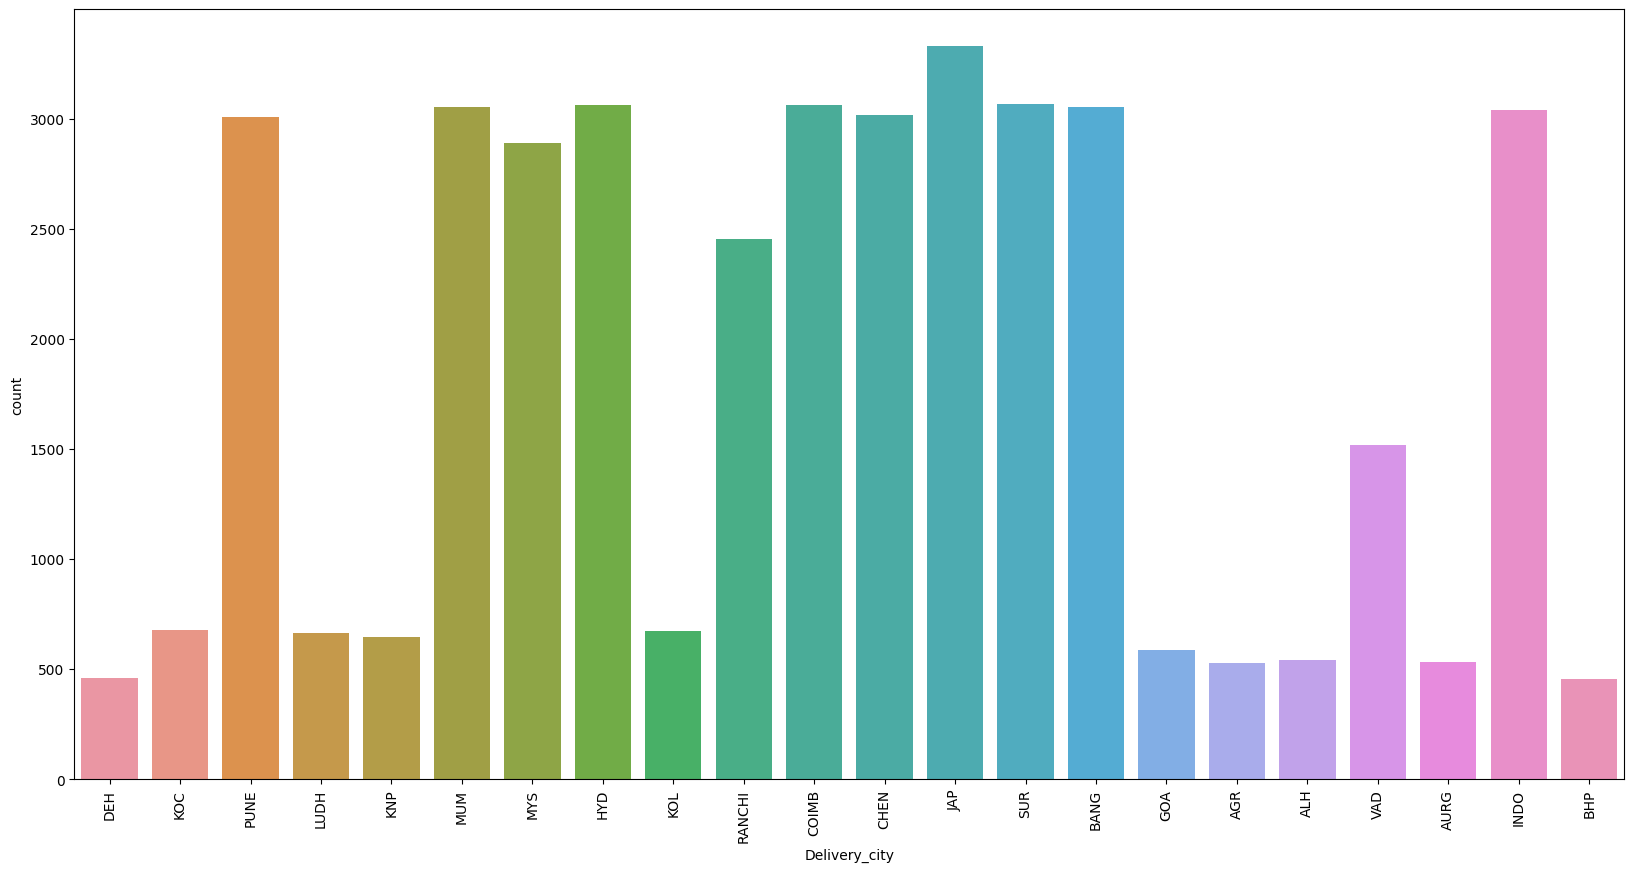

In [69]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Delivery_city'])
plt.xticks(rotation = 'vertical')
plt.show()

In [70]:
df.columns

Index(['Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings',
       'Restaurant_latitude', 'Restaurant_longitude',
       'Delivery_location_latitude', 'Delivery_location_longitude',
       'Time_Order_picked', 'Weather_conditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken (min)', 'Year',
       'Month', 'Day', 'TimeOrder_Hour', 'TimeOrder_Min',
       'Time_Order_picked_hour', 'Time_Order_picked_min', 'Delivery_city',
       'Distance'],
      dtype='object')

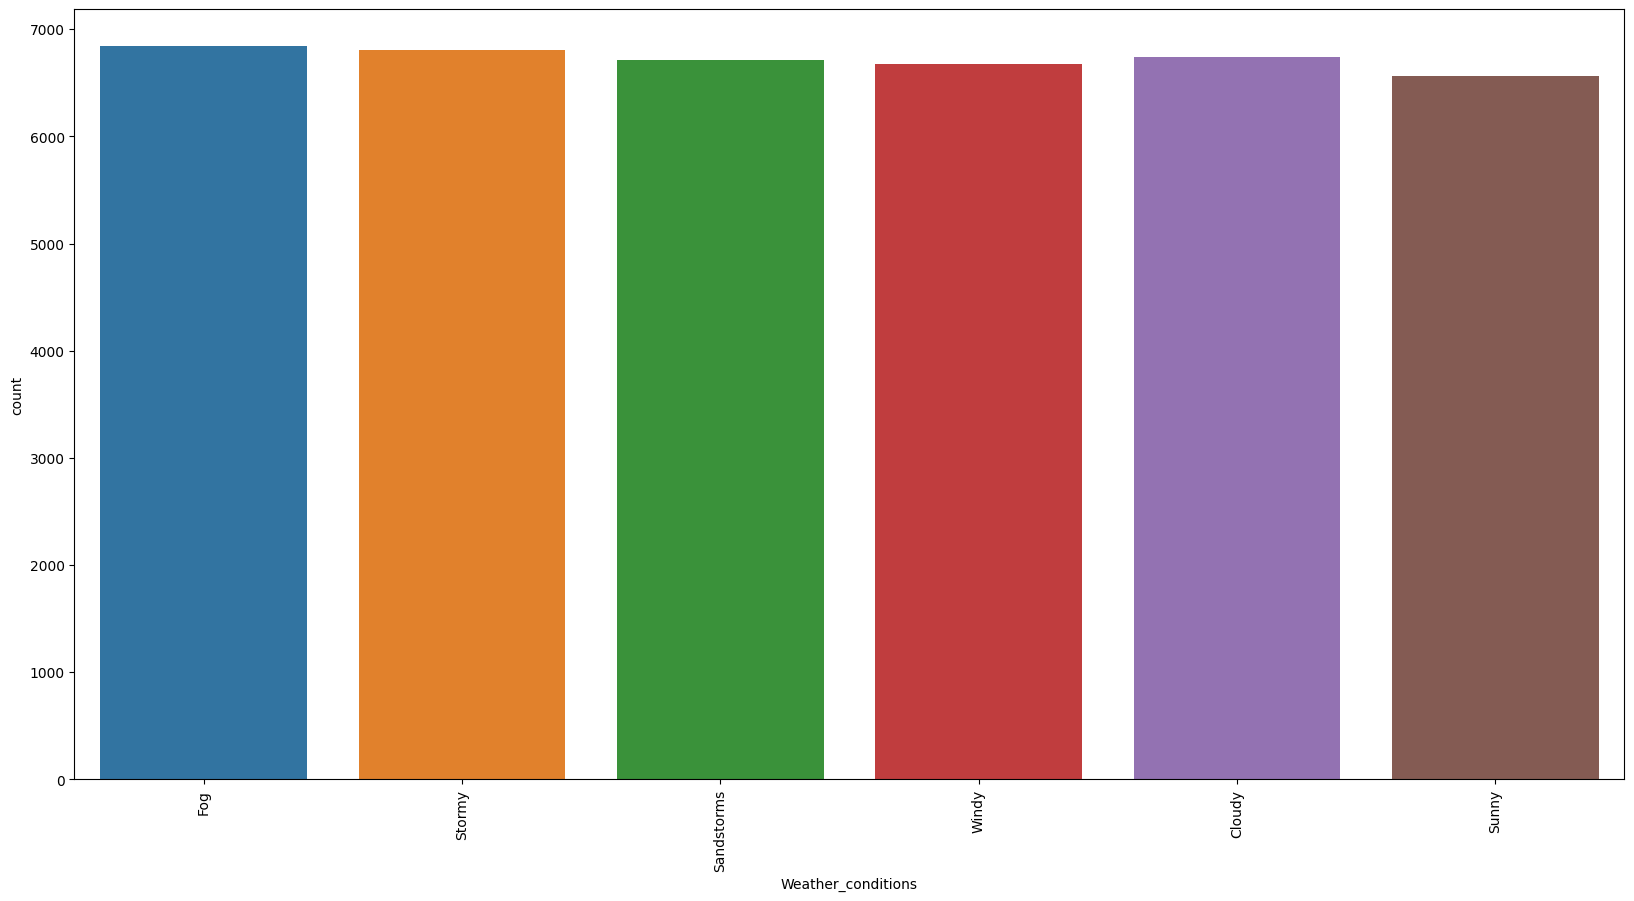

In [71]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Weather_conditions'])
plt.xticks(rotation = 'vertical')
plt.show()

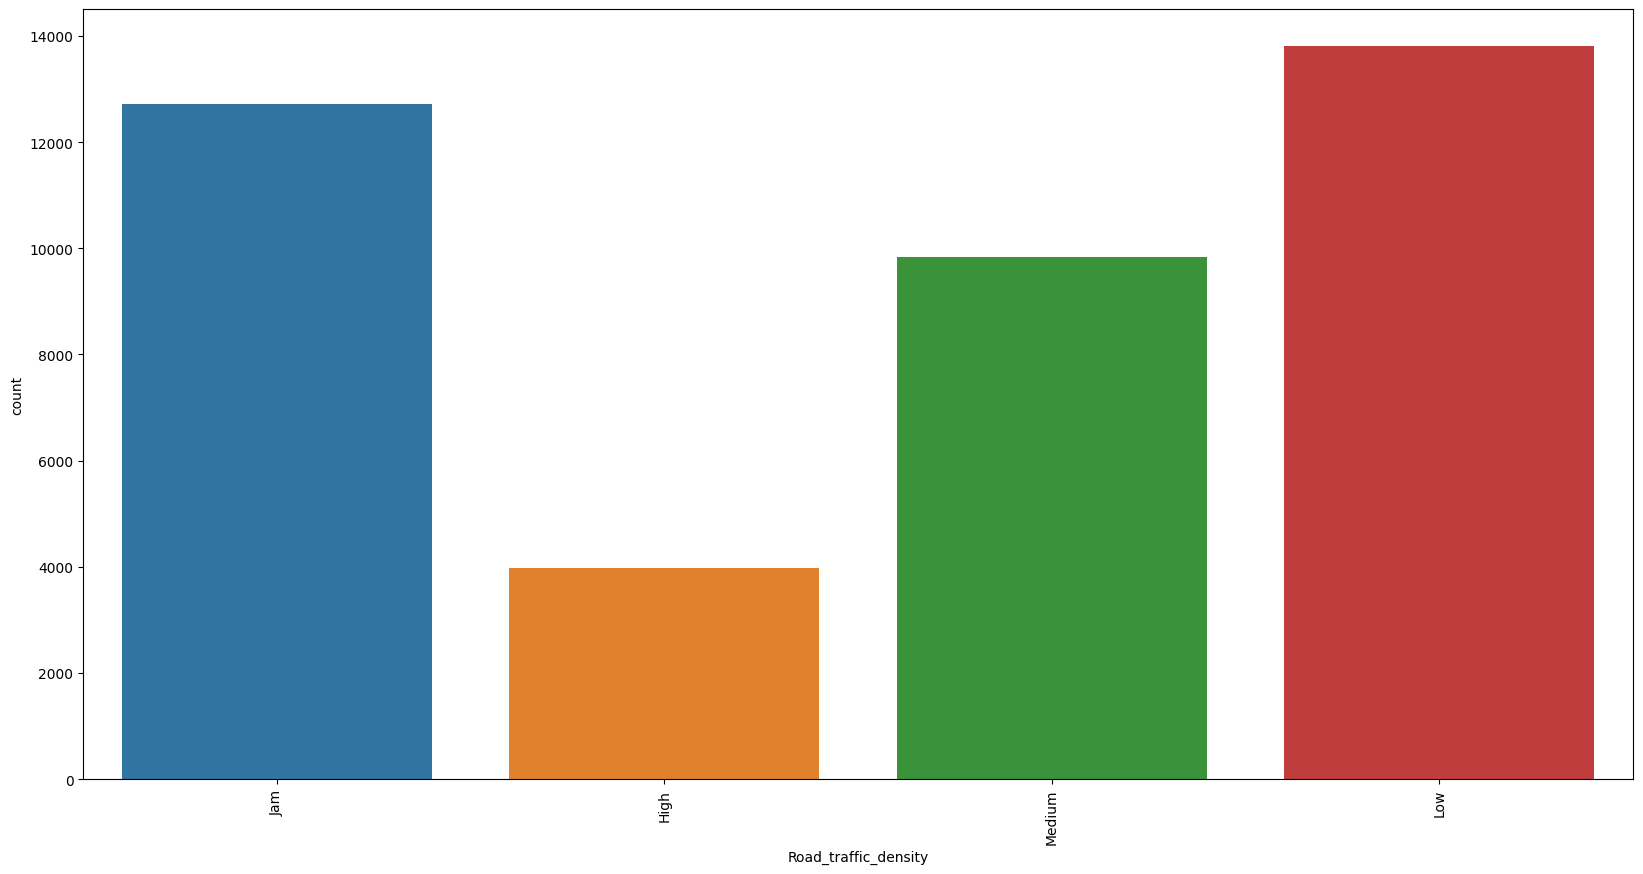

In [72]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Road_traffic_density'])
plt.xticks(rotation = 'vertical')
plt.show()

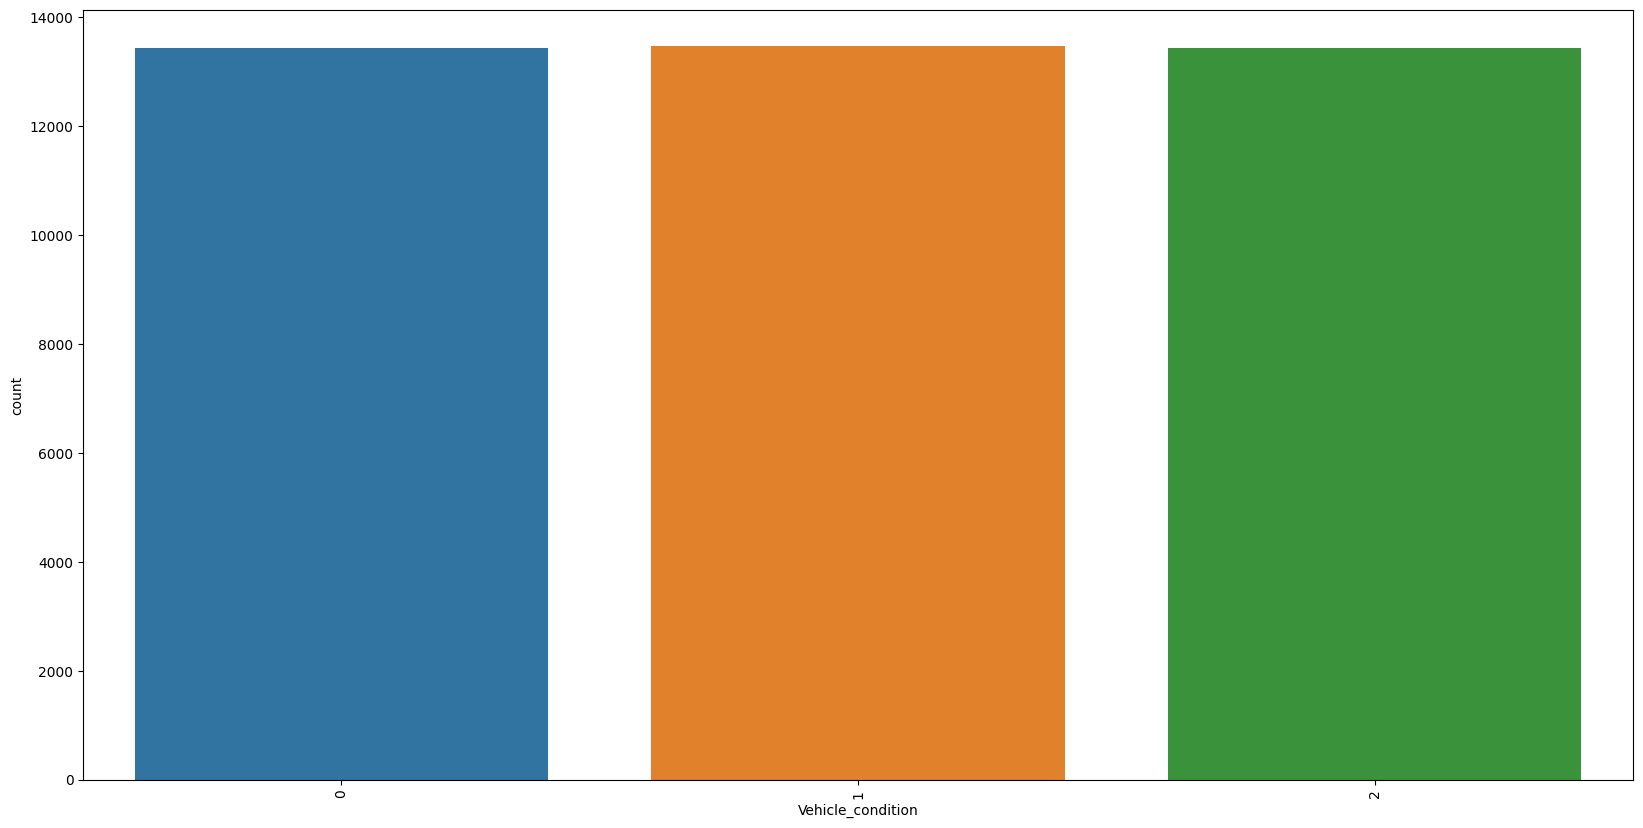

In [73]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Vehicle_condition'])
plt.xticks(rotation = 'vertical')
plt.show()

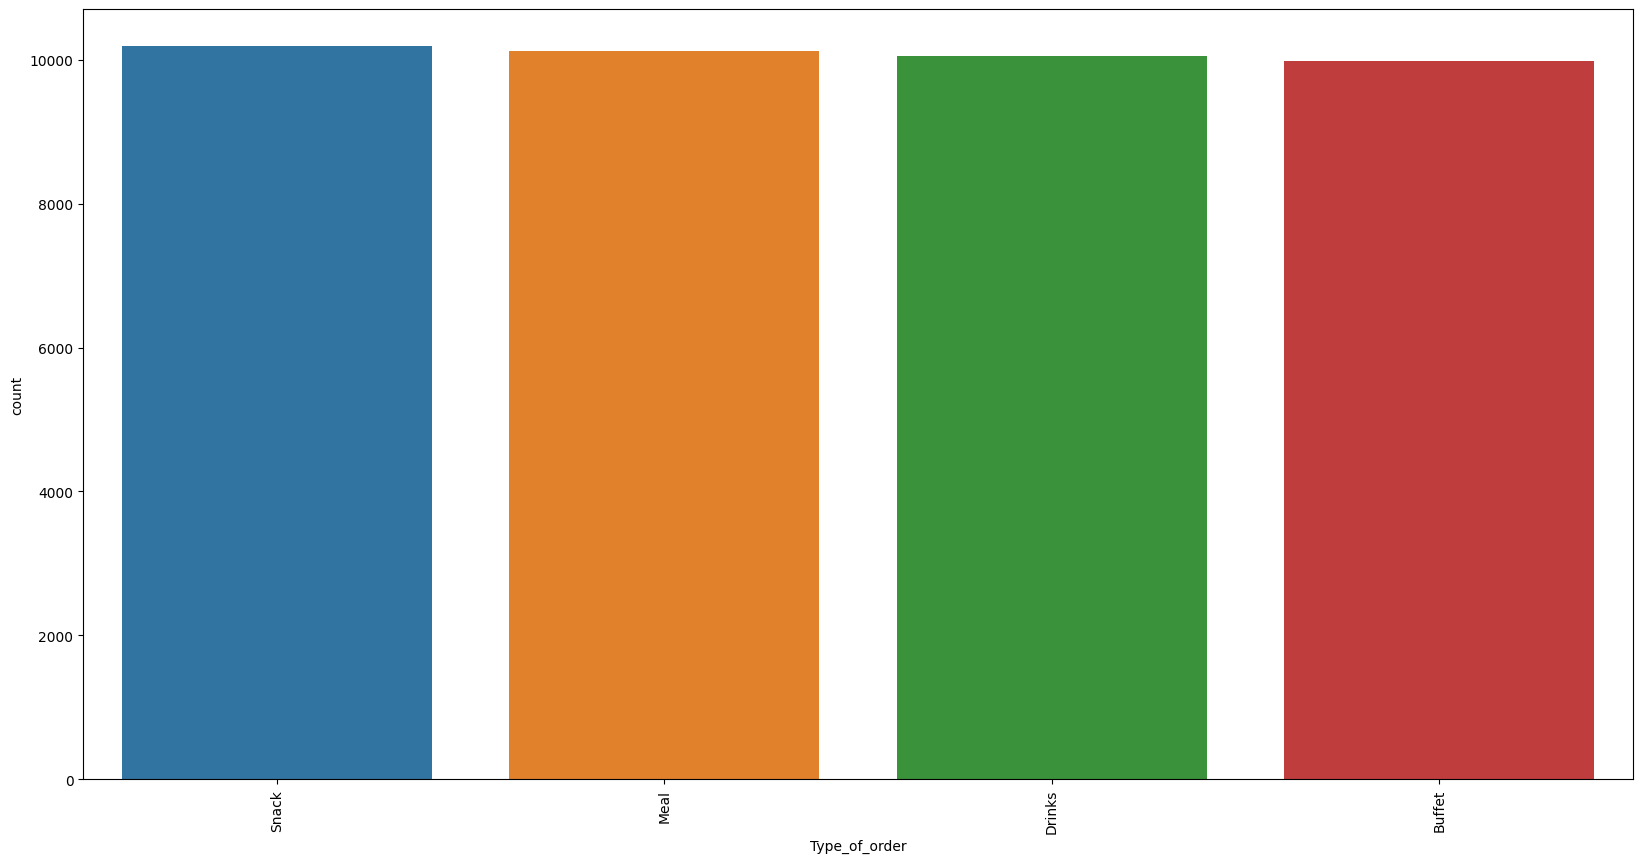

In [74]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Type_of_order'])
plt.xticks(rotation = 'vertical')
plt.show()

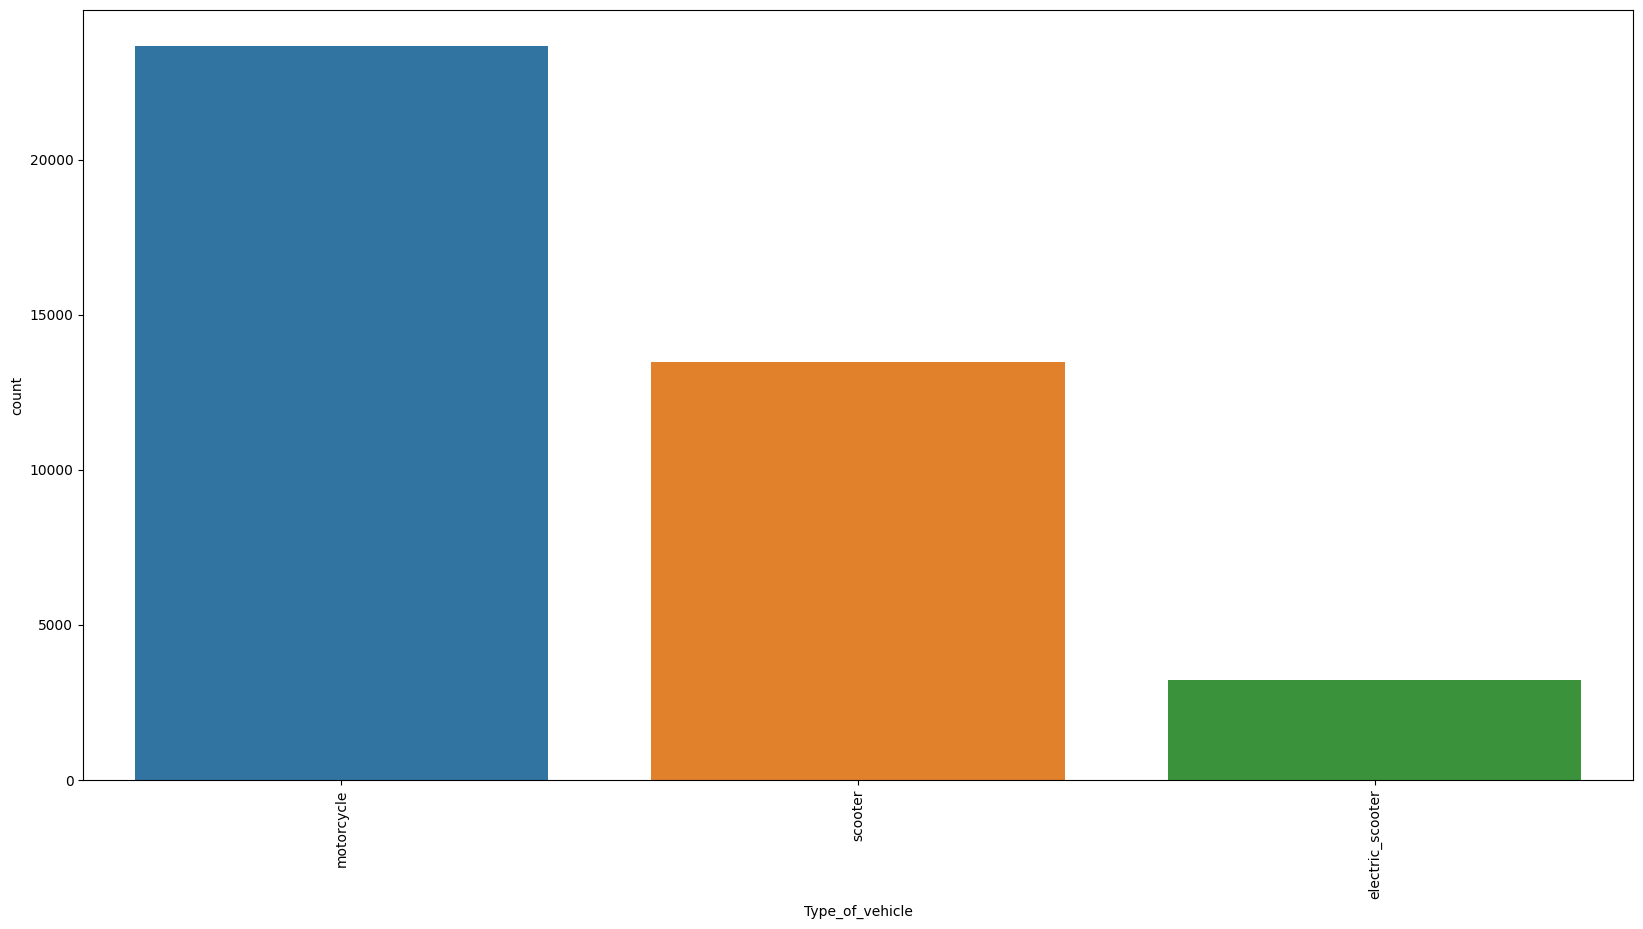

In [75]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Type_of_vehicle'])
plt.xticks(rotation = 'vertical')
plt.show()

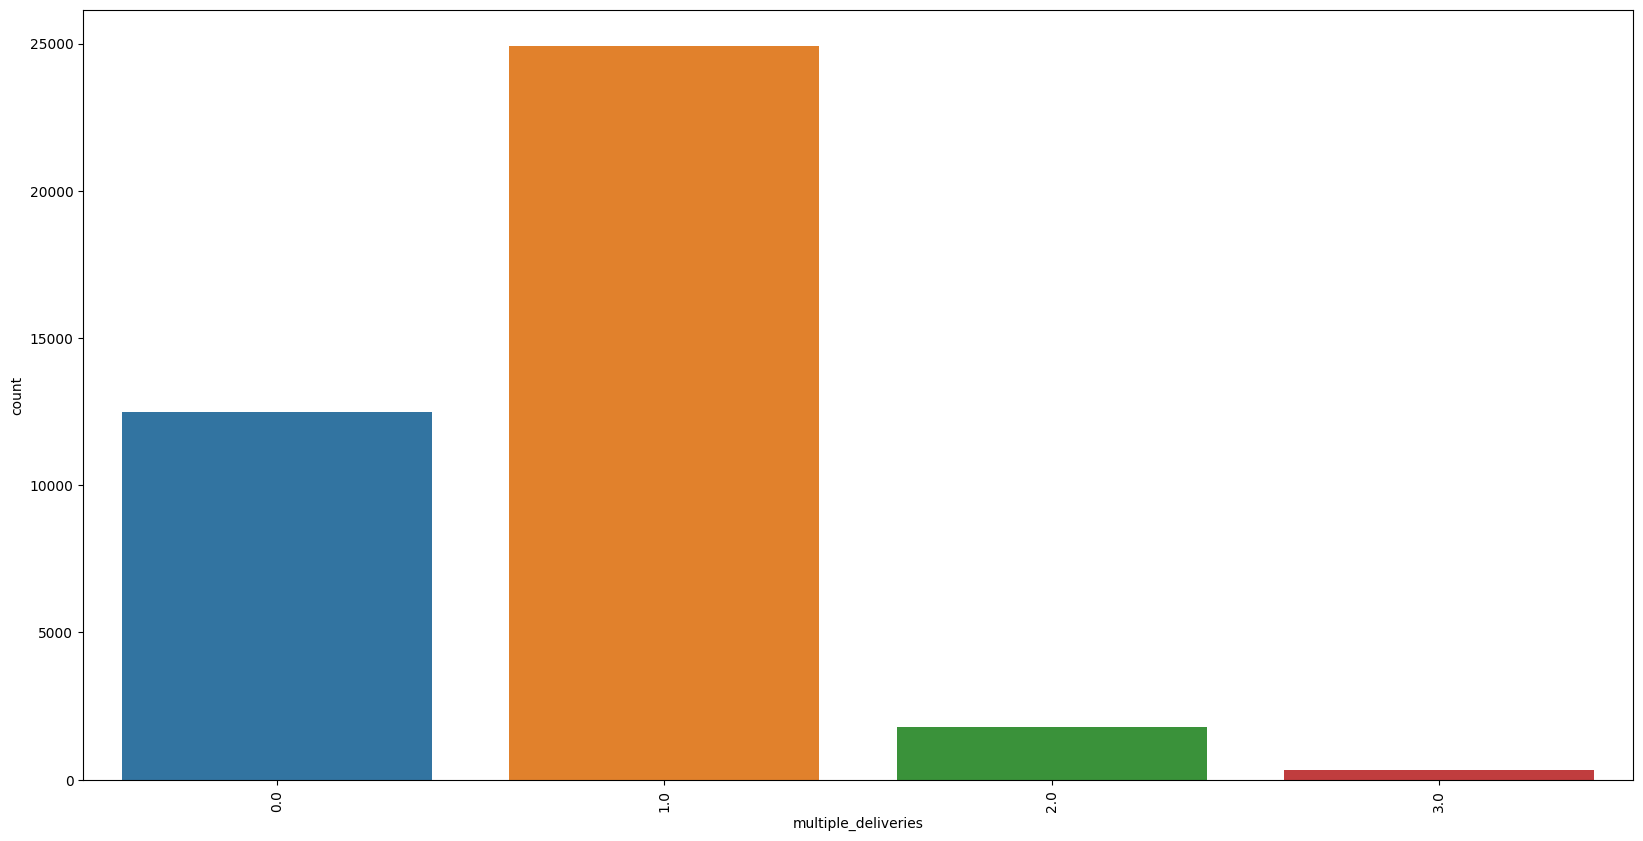

In [76]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['multiple_deliveries'])
plt.xticks(rotation = 'vertical')
plt.show()

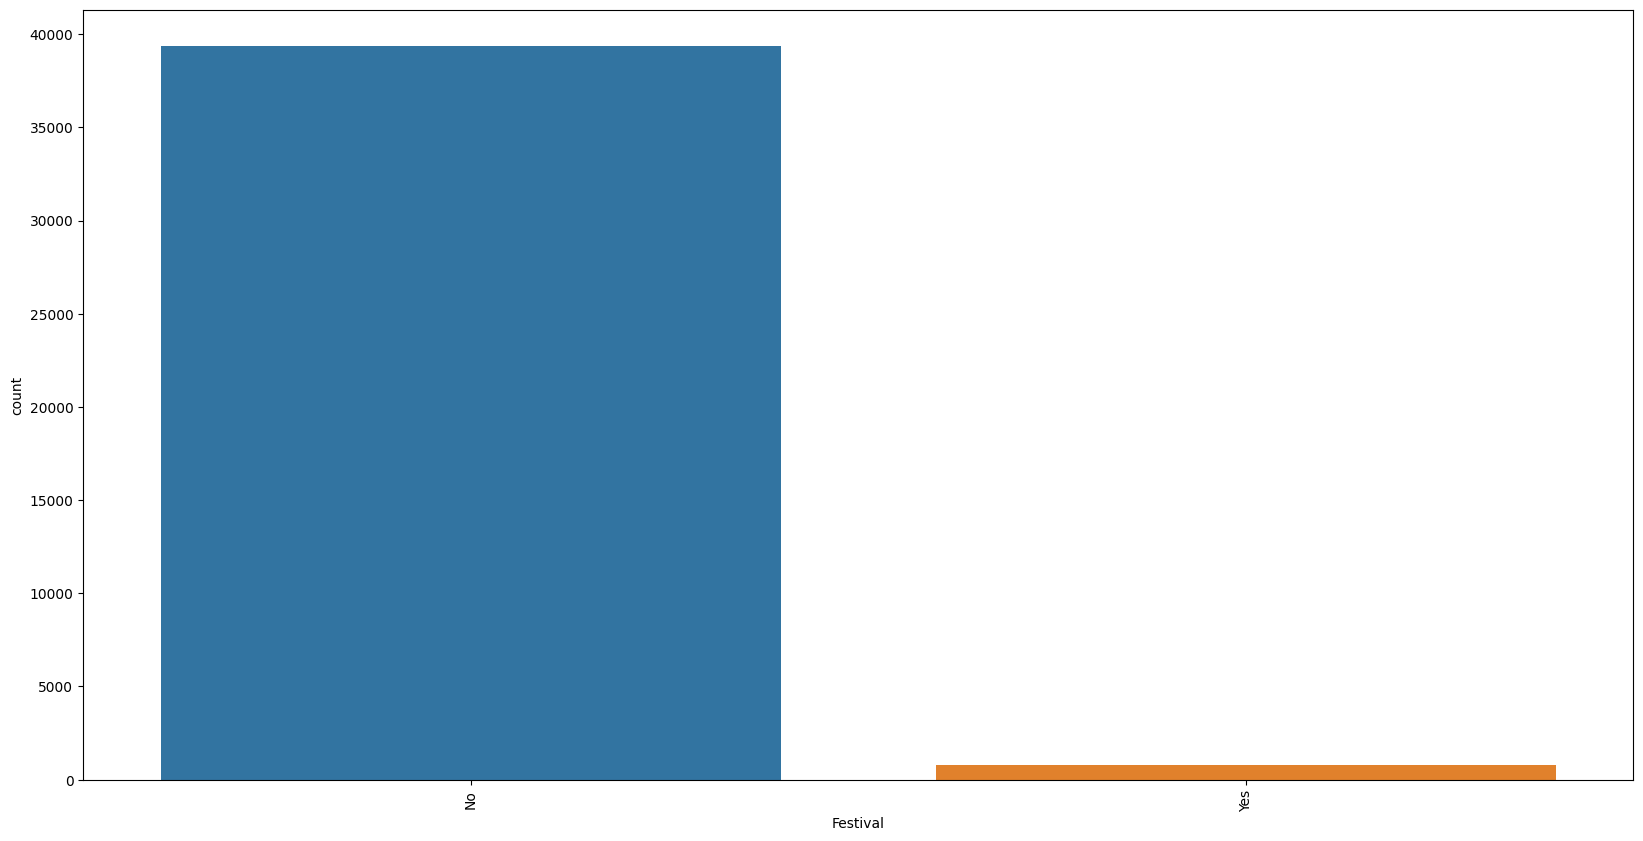

In [77]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Festival'])
plt.xticks(rotation = 'vertical')
plt.show()

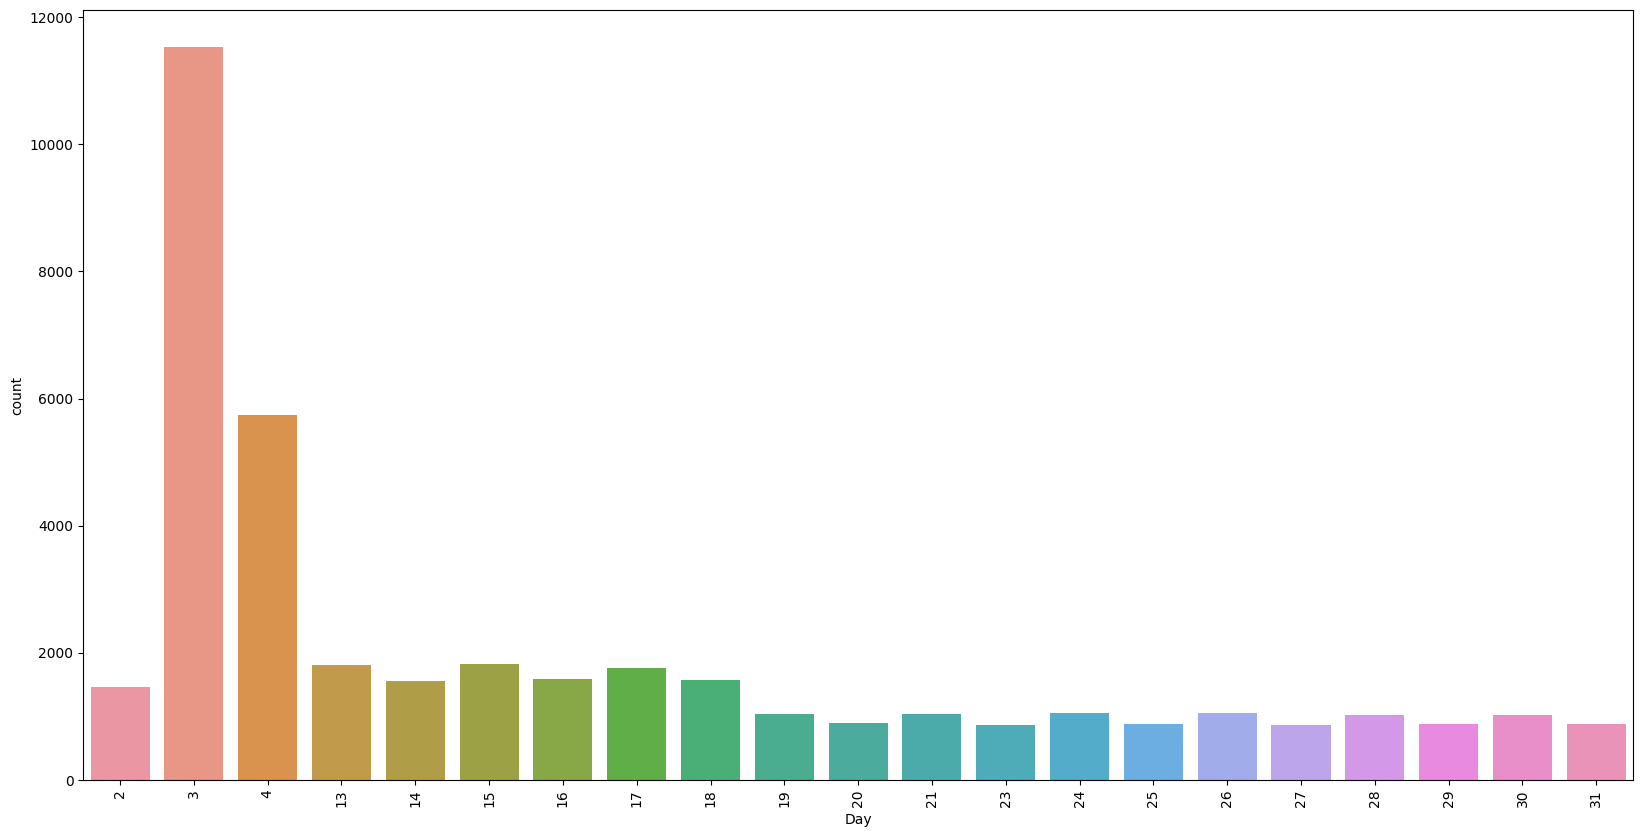

In [78]:
plt.figure(figsize=(20,10))
sns.countplot(df , x=df['Day'])
plt.xticks(rotation = 'vertical')
plt.show()

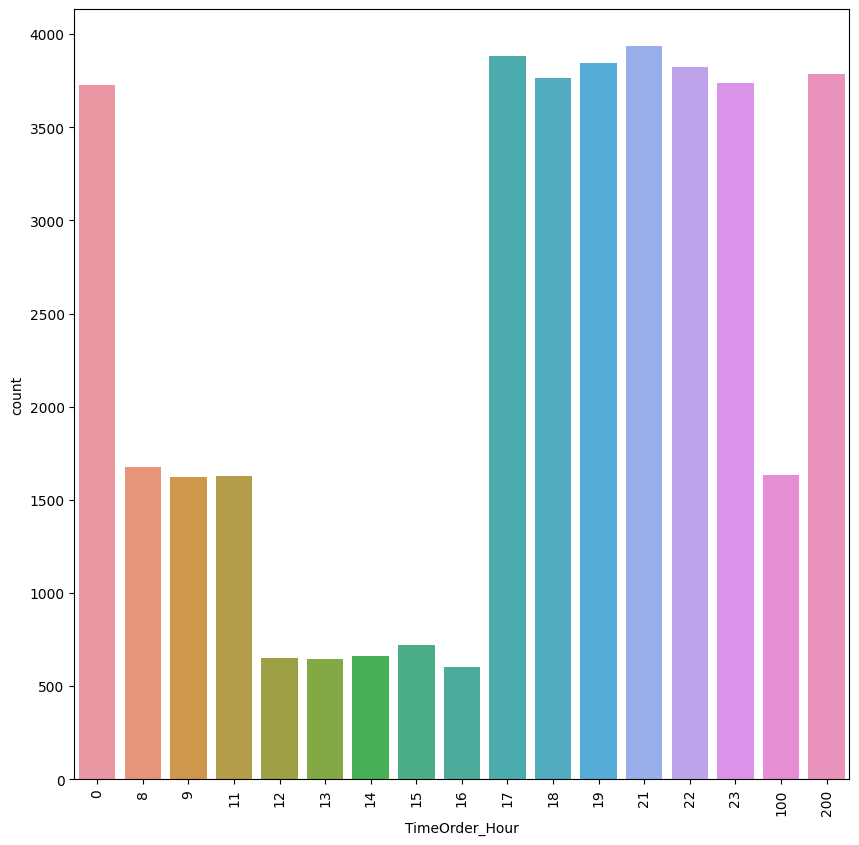

In [79]:
plt.figure(figsize=(10,10))
sns.countplot(df , x=df['TimeOrder_Hour'])
plt.xticks(rotation = 'vertical')
plt.show()

In [80]:
# more no. of order is b/w 8 -11 and eveing 5 to night 12
# people more ofter deliver food in the evening and morning time
df.groupby(['Delivery_city']).median().reset_index()

,Delivery_city,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken (min),Year,Month,Day,TimeOrder_Hour,TimeOrder_Min,Time_Order_picked_hour,Time_Order_picked_min,Distance
0,AGR,29.0,4.7,27.161694,78.042990,27.231850,78.100165,1.0,1.0,26.0,2022.0,2.0,15.0,19.0,55.0,19.0,35.0,10.416889
1,ALH,30.0,4.7,25.451646,81.834502,25.519872,81.904492,1.0,1.0,27.0,2022.0,2.0,14.0,19.0,83.0,19.0,35.0,10.485604
2,AURG,30.0,4.7,19.876106,75.340775,19.935337,75.402353,1.0,1.0,26.0,2022.0,2.0,15.0,19.0,58.0,18.0,35.0,9.157670
3,BANG,30.0,4.7,12.970221,77.640489,13.015662,77.695396,1.0,1.0,25.0,2022.0,3.0,13.0,19.0,79.0,18.0,35.0,9.315069
4,BHP,30.0,4.7,23.232357,77.429845,23.291943,77.479399,1.0,1.0,26.0,2022.0,2.0,15.0,18.0,83.0,18.0,35.0,9.059835
5,CHEN,30.0,4.7,13.044694,80.242439,13.096438,80.299982,1.0,1.0,26.0,2022.0,3.0,13.0,19.0,75.0,18.0,35.0,9.313980
6,COIMB,30.0,4.7,11.010375,76.976494,11.071278,77.037003,1.0,1.0,26.0,2022.0,3.0,13.0,19.0,83.0,18.0,35.0,9.348206
7,DEH,30.0,4.7,30.342509,78.061187,30.411281,78.126106,1.0,1.0,26.0,2022.0,2.0,14.0,19.0,91.0,19.0,35.0,10.278861
8,GOA,30.0,4.7,15.544419,73.766668,15.589600,73.838172,1.0,1.0,26.0,2022.0,2.0,14.0,19.0,75.0,18.0,35.0,9.263232
9,HYD,30.0,4.7,17.431477,78.400350,17.498263,78.465467,1.0,1.0,26.0,2022.0,3.0,13.0,19.0,83.0,18.0,35.0,9.220373


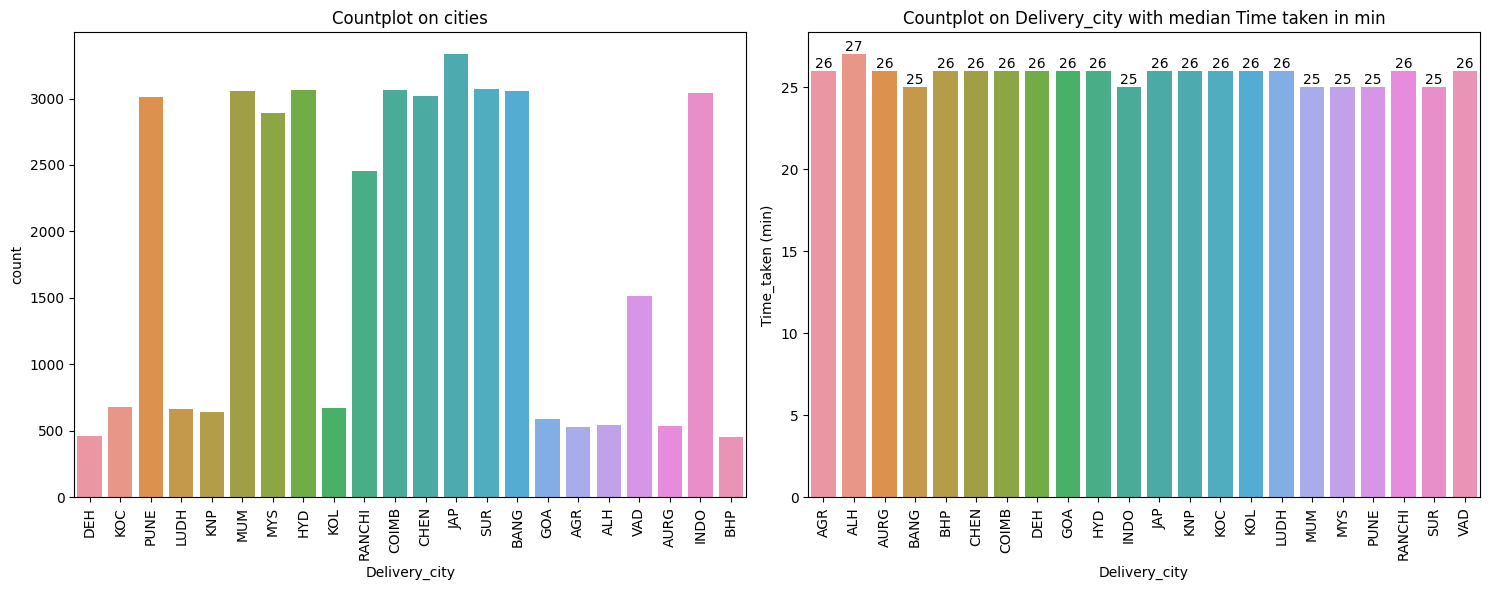

In [81]:
# plotting a countplot of Festival and bar plot w.r.t median time taken min
plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
sns.countplot(data=df,x=df['Delivery_city'])
plt.title("Countplot on cities")
plt.xticks(rotation = 'vertical')

plt.subplot(1,2,2)
data1 = df.groupby(['Delivery_city']).median().reset_index()
ax = sns.barplot(x='Delivery_city', y='Time_taken (min)',
                data=data1,errwidth=0)
plt.title('Countplot on Delivery_city with median Time taken in min')
plt.xticks(rotation = 'vertical')

plt.tight_layout()

for i in ax.containers:
    ax.bar_label(i,)

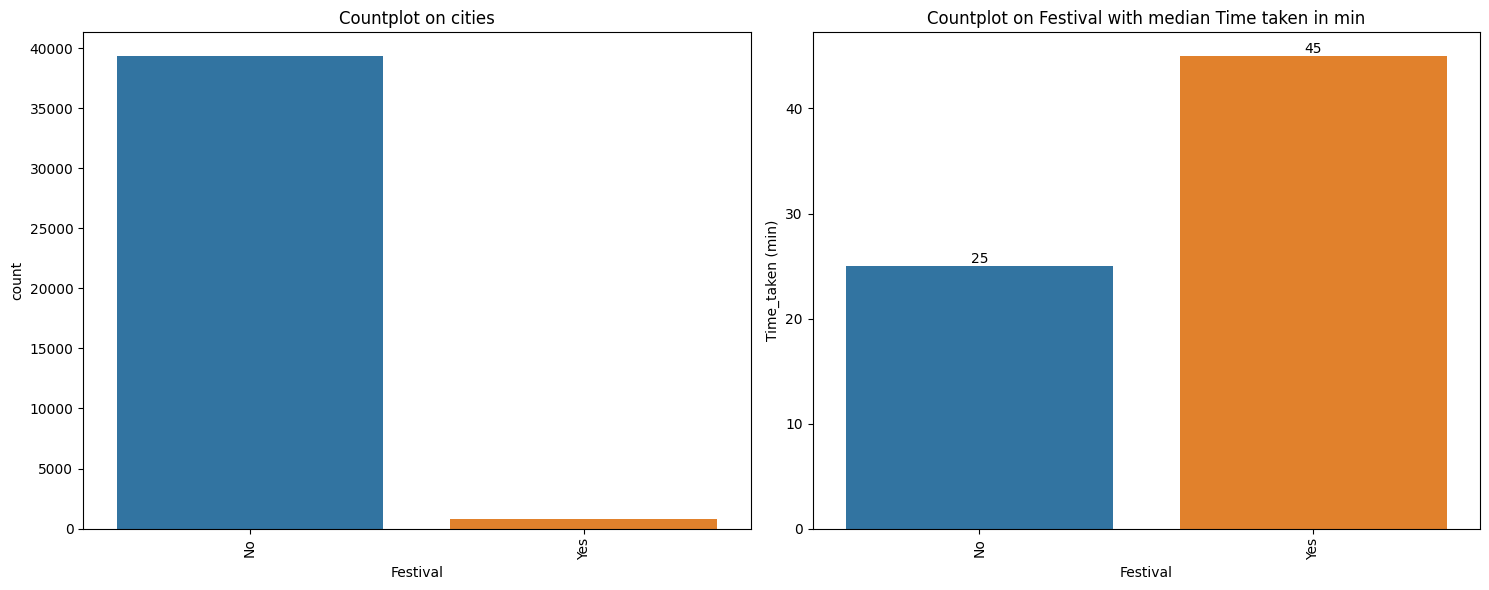

In [82]:
# plotting a countplot of Festival and bar plot w.r.t median time taken min
# plotting a countplot of Festival and bar plot w.r.t median time taken min
plt.figure(figsize=(15,6))

plt.subplot(1,2,1)
sns.countplot(data=df,x=df['Festival'])
plt.title("Countplot on cities")
plt.xticks(rotation = 'vertical')

plt.subplot(1,2,2)
data1 = df.groupby(['Festival']).median().reset_index()
ax = sns.barplot(x='Festival', y='Time_taken (min)',
                data=data1,errwidth=0)
plt.title('Countplot on Festival with median Time taken in min')
plt.xticks(rotation = 'vertical')

plt.tight_layout()

for i in ax.containers:
    ax.bar_label(i,)

In [83]:
numrical_feature = df.select_dtypes(exclude= 'object').columns.to_list()
numrical_feature

['Delivery_person_Age',
 'Delivery_person_Ratings',
 'Restaurant_latitude',
 'Restaurant_longitude',
 'Delivery_location_latitude',
 'Delivery_location_longitude',
 'Vehicle_condition',
 'multiple_deliveries',
 'Time_taken (min)',
 'Year',
 'Month',
 'Day',
 'TimeOrder_Hour',
 'TimeOrder_Min',
 'Time_Order_picked_hour',
 'Time_Order_picked_min',
 'Distance']

In [84]:
df.isnull().sum()

Delivery_person_ID                0
Delivery_person_Age             200
Delivery_person_Ratings           0
Restaurant_latitude               0
Restaurant_longitude              0
Delivery_location_latitude        0
Delivery_location_longitude       0
Time_Order_picked                 0
Weather_conditions                0
Road_traffic_density              0
Vehicle_condition                 0
Type_of_order                     0
Type_of_vehicle                   0
multiple_deliveries             855
Festival                        206
City                           1059
Time_taken (min)                  0
Year                              0
Month                             0
Day                               0
TimeOrder_Hour                    0
TimeOrder_Min                     0
Time_Order_picked_hour            0
Time_Order_picked_min             0
Delivery_city                     0
Distance                          0
dtype: int64

In [85]:
#Drop Delivery_person_ID column
df.drop(columns=['Delivery_person_ID'] ,inplace=True)

In [86]:
#Drop Time_Order_picked and Time_Orderd
df.drop(columns=['Time_Order_picked' ] ,inplace=True)

In [87]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Weather_conditions',
       'Road_traffic_density', 'Vehicle_condition', 'Type_of_order',
       'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City',
       'Time_taken (min)', 'Year', 'Month', 'Day', 'TimeOrder_Hour',
       'TimeOrder_Min', 'Time_Order_picked_hour', 'Time_Order_picked_min',
       'Delivery_city', 'Distance'],
      dtype='object')

In [88]:
df.shape

(40344, 24)

In [89]:
#Drop Unnecessory columns
df.drop(columns=['Restaurant_latitude' ,'Restaurant_longitude' ,'Delivery_location_latitude' ,'Delivery_location_longitude' ,'Year' ,'Month' ,'Day' ,'TimeOrder_Min' ,'Time_Order_picked_hour' ,'Time_Order_picked_min'] ,axis=1 ,inplace=True)

In [90]:
df.head()

,Delivery_person_Age,Delivery_person_Ratings,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),TimeOrder_Hour,Delivery_city,Distance
0,36.0,4.2,Fog,Jam,2,Snack,motorcycle,3.0,No,Metropolitian,46,21,DEH,10.280582
1,21.0,4.7,Stormy,High,1,Meal,motorcycle,1.0,No,Metropolitian,23,14,KOC,6.242319
2,23.0,4.7,Sandstorms,Medium,1,Drinks,scooter,1.0,No,Metropolitian,21,17,PUNE,13.787860
3,34.0,4.3,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,9,LUDH,2.930258
4,24.0,4.7,Fog,Jam,1,Snack,scooter,1.0,No,Metropolitian,41,19,KNP,19.396618


### Split Dataset

In [91]:
x = df.drop(columns=['Time_taken (min)'] ,axis=1)
y = df[['Time_taken (min)']]

In [92]:
num_col = x.select_dtypes(exclude= 'object').columns.to_list()
cat_col = x.select_dtypes(include= 'object').columns.to_list()

In [93]:
df[df['Road_traffic_density'] == 'Low']

,Delivery_person_Age,Delivery_person_Ratings,Weather_conditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken (min),TimeOrder_Hour,Delivery_city,Distance
3,34.0,4.3,Sandstorms,Low,0,Buffet,motorcycle,0.0,No,Metropolitian,20,9,LUDH,2.930258
11,31.0,4.7,Sandstorms,Low,2,Meal,electric_scooter,0.0,No,Metropolitian,26,22,RANCHI,19.618739
12,37.0,5.0,Sandstorms,Low,1,Snack,motorcycle,1.0,No,Metropolitian,20,8,COIMB,1.558132
17,35.0,4.3,Cloudy,Low,1,Drinks,scooter,0.0,No,Metropolitian,38,23,SUR,13.682045
19,23.0,4.8,Windy,Low,2,Buffet,electric_scooter,0.0,No,Urban,12,23,PUNE,16.853619
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45569,30.0,4.9,Windy,Low,1,Snack,motorcycle,1.0,No,Metropolitian,26,100,COIMB,3.116127
45571,34.0,4.9,Sandstorms,Low,1,Snack,scooter,1.0,No,NaN,26,9,MYS,3.109134
45573,30.0,4.6,Cloudy,Low,0,Meal,motorcycle,0.0,No,Metropolitian,20,0,PUNE,3.064267
45575,37.0,4.8,Sandstorms,Low,2,Drinks,electric_scooter,0.0,No,Metropolitian,20,9,CHEN,3.104827


##### If traffic density is LOW our delivery person will easily deliver food and take less time
##### Also that person will easily deliver food if weather condition is SUNNY
##### WE have to convert them with the help of ordinalencoder
##### for remaining column we can use any other encoder as order is not matter

In [94]:
road_traffic = ['Low' ,'Medium' ,'High' ,'Jam']
weather_cond = ['Sunny' ,'Cloudy' ,'Windy' ,'Fog' ,'Sandstorms' ,'Stormy']

num_col


['Delivery_person_Age',
 'Delivery_person_Ratings',
 'Vehicle_condition',
 'multiple_deliveries',
 'TimeOrder_Hour',
 'Distance']

In [95]:
nominal_encodeing_col = ['Type_of_order','Type_of_vehicle','Festival','City','Delivery_city'] 
ordinal_encoding_col = ['Weather_conditions','Road_traffic_density']
numerical_col = num_col
nominal_encodeing_col 
numerical_col


['Delivery_person_Age',
 'Delivery_person_Ratings',
 'Vehicle_condition',
 'multiple_deliveries',
 'TimeOrder_Hour',
 'Distance']

In [96]:
#Define Pipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [97]:
#numerical_pipeline

numerical_pipeline = Pipeline(
    steps=[
        ('imputer' ,SimpleImputer(strategy='constant',fill_value=0) ),
        ('scalar' ,StandardScaler(with_mean=False))
    ]
)



#Categorical Pipeline for ordinal data column
ordinal_pipeline = Pipeline(
    steps=[
        ('imputer' ,SimpleImputer(strategy='most_frequent')),
        ('encoder' ,OrdinalEncoder(categories=[weather_cond ,road_traffic])),
        ('scalar' ,StandardScaler(with_mean=False))
    ]
)



#Categorical Pipeline for nominal data column
nominal_pipeline = Pipeline(
    steps=[
        ('imputer' ,SimpleImputer(strategy='most_frequent')),
        ('encoder' ,OneHotEncoder(handle_unknown='ignore')),
        ('scalar' ,StandardScaler(with_mean=False))
    ]
)

In [98]:
preprocessor = ColumnTransformer([
    ('numerical_pipeline' , numerical_pipeline ,numerical_col),
    ('nominal_pipeline' ,nominal_pipeline ,nominal_encodeing_col),
    ('categorical_pipeline' , ordinal_pipeline ,ordinal_encoding_col)
])

In [99]:
df.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'Weather_conditions',
       'Road_traffic_density', 'Vehicle_condition', 'Type_of_order',
       'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City',
       'Time_taken (min)', 'TimeOrder_Hour', 'Delivery_city', 'Distance'],
      dtype='object')

In [100]:
df['multiple_deliveries'].unique()

array([ 3.,  1.,  0., nan,  2.])

In [101]:
x_train ,x_test ,y_train ,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [102]:
x_train = preprocessor.fit_transform(x_train)
x_test =preprocessor.transform(x_test)

In [112]:
x_test.shape

(8069, 42)

#### Defining Model

In [103]:
from sklearn.linear_model import LinearRegression ,Lasso ,Ridge ,ElasticNet
from sklearn.tree import DecisionTreeRegressor 
from sklearn.svm import SVR 
from sklearn.ensemble import RandomForestRegressor 
from sklearn.ensemble import GradientBoostingRegressor 
from xgboost import XGBRegressor
from sklearn.metrics import r2_score ,mean_absolute_error ,mean_squared_error


In [104]:
def evaluate(true , predicted):
    r2 = r2_score(true ,predicted)
    MAE =mean_absolute_error(true ,predicted )
    MSE =mean_squared_error(true ,predicted )
    rmse =np.sqrt(MSE)
    
    return r2 ,MAE ,MSE ,rmse



In [105]:
models ={
    'linerar regression':LinearRegression(),
    'Lasso' : Lasso(),
    'Ridge' : Ridge(),
    'ElasticNet' : ElasticNet(),
    'Random Forest' : RandomForestRegressor(),
    'DecisionTreeRegressor' : DecisionTreeRegressor(),
    'SVR' : SVR(),
    'GradientBoostRegressor' : GradientBoostingRegressor(),
    'XGBRegressor' : XGBRegressor()
}

train_r2_list =[]
train_MAE_list = []
train_MSE_list = []
train_rmse_list = []
train_model_list= []

test_r2_list =[]
test_MAE_list = []
test_MSE_list = []
test_rmse_list = []
test_model_list= []


In [106]:
for i in range(len(list(models.values()))):
    model = list(models.values())[i]
    #train model
    model.fit(x_train ,y_train)  
    
    
    #predict output
    y_train_pred = model.predict(x_train )
    y_test_pred = model.predict(x_test )
    
    
    #Evaluate Model on test data
    r2_test ,mae_test ,mse_test ,rmse_test =evaluate(y_test_pred ,y_test)
    
    #Evaluate Model on train data
    r2_train ,mae_train ,mse_train ,rmse_train =evaluate(y_train_pred ,y_train)
    
    
    
    
    #create list from train model 
    train_model_list.append(list(models.keys())[i])
    
    #create list from r2_score for train data
    train_r2_list.append(r2_train)
    
    #create list from mae_train for train data
    train_MAE_list.append(mae_train)
    
    #create list from mse_train for train data
    train_MSE_list.append(mse_train)
    
    #create list from rmse_train for train data
    train_rmse_list.append(rmse_train)
    
    
    
    
    
    #create list from test model 
    test_model_list.append(list(models.keys())[i])
    
    #create list from r2_score for test data
    test_r2_list.append(r2_test)
    
    #create list from mae_train for test data
    test_MAE_list.append(mae_test)
    
    #create list from mse_train for test data
    test_MSE_list.append(mse_test)
    
    #create list from rmse_train for test data
    test_rmse_list.append(rmse_test)
    
    
    
    
    
    
    print(f'Model Performance on train Data for model {list(models.keys())[i]}')
    print(f"R2_score for model {r2_train}")
    print(f"MAE of train data {mae_train}")
    print(f"MSE of train data {mse_train}")
    print(f"RMSE of train data {rmse_train}")
    
    print(35*"*")
    
    print(f'Model Performance on test Data for model {list(models.keys())[i]}')
    print(f"R2_score for model {r2}")
    print(f"MAE of train data {mae}")
    print(f"MSE of train data {mse}")
    print(f"RMSE of train data {rmse}")
    
    print(35*"*")
    print(35*"*")
    print('\n')
    print('\n')
    
    
    
    
    

Model Performance on train Data for model linerar regression
R2_score for model 0.1455453182983717
MAE of train data 5.0383598591208365
MSE of train data 40.30542863743883
RMSE of train data 6.348655655919513
***********************************
Model Performance on test Data for model linerar regression


NameError: name 'r2' is not defined

In [ ]:
Train_df = pd.DataFrame(
    {'Model_Name':train_model_list,
    "Train_R2_score":train_r2_list,
    'Train_MAE':train_MAE_list,
    'Train_MSE':train_MSE_list,
    'Train_RMSE':train_rmse_list
    }
)

Test_df = pd.DataFrame(
    {
        'Model_Name':test_model_list,
        'Test_R2_score':test_r2_list,
        'Test_MAE':test_MAE_list,
        'Test_MSE':test_MSE_list,
        'Test_RMSE':test_rmse_list
    }
)

In [ ]:
Train_df

,Model_Name,Train_R2_score,Train_MAE,Train_MSE,Train_RMSE
0,linerar regression,0.145545,5.038360,40.305429,6.348656
1,Lasso,-1.158822,5.449047,46.455910,6.815857
2,Ridge,0.145495,5.038338,40.305025,6.348624
3,ElasticNet,-1.439536,5.501711,46.872030,6.846315
4,Random Forest,0.973429,1.147807,2.110438,1.452735
5,DecisionTreeRegressor,1.000000,0.000000,0.000000,0.000000
6,SVR,0.147674,4.894194,38.746811,6.224694
7,GradientBoostRegressor,0.698508,3.515617,19.233946,4.385652
8,XGBRegressor,0.851570,2.639025,10.871468,3.297191


In [ ]:
Test_df

,Model_Name,Test_R2_score,Test_MAE,Test_MSE,Test_RMSE
0,linerar regression,0.113513,5.132537,41.507874,6.442660
1,Lasso,-1.230660,5.545679,47.798233,6.913627
2,Ridge,0.113318,5.132762,41.512615,6.443028
3,ElasticNet,-1.517000,5.590869,48.208792,6.943255
4,Random Forest,0.795725,3.131610,15.298876,3.911378
5,DecisionTreeRegressor,0.684088,4.048705,27.901971,5.282232
6,SVR,0.107609,5.003171,39.930366,6.319048
7,GradientBoostRegressor,0.681635,3.577222,19.987838,4.470776
8,XGBRegressor,0.788968,3.139117,15.298211,3.911293


## Best Model  
### random forest with 82% accuracy

In [ ]:

print("Food Delivery Time Prediction")
# a = int(input("Age of Delivery Partner: "))
# b = float(input("Ratings of Previous Deliveries: "))
# c = int(input("Total Distance: "))

a=25
b=4.3
c=12

features = np.array([[a, b, c]])
print("Predicted Delivery Time in Minutes = ", model.predict(features))

Food Delivery Time Prediction


ValueError: X has 3 features, but LinearRegression is expecting 42 features as input.

In [ ]:
x_train[0].size


42